# 08 · Notebook-only checks (not in the paper)
How each method searched, AUC vs time, and the different-settings count per run.

In [1]:
import os
from pathlib import Path
import pandas as pd
from IPython.display import display
from hpo import config, data, spaces, starts, methods, runner, stats, plots

pd.set_option("display.precision", 5)
# Results folder: the full run by default. Set HPO_RESULTS=smoke to read the smoke test.
RESULTS = (
    config.SMOKE_DIR if os.environ.get("HPO_RESULTS") == "smoke" else config.RESULTS_DIR
)
FIGS, TABLES = RESULTS / "figures", RESULTS / "tables"
TABLES.mkdir(parents=True, exist_ok=True)
print("Reading/writing:", RESULTS.relative_to(config.ROOT))

Reading/writing: results


In [2]:
runs, curves = stats.load(RESULTS)
ds = stats.distinct_settings(curves)
ds.groupby(["model", "method"])["distinct"].describe()[["mean", "min", "max"]].round(1)

mean    min    max
model method                     
rf    de      255.2  252.0  256.0
      ga      122.4  106.0  146.0
      grid    256.0  256.0  256.0
      pso     254.5  251.0  255.0
      random  256.0  256.0  256.0
svm   de      255.0  252.0  256.0
      ga       74.3   64.0   85.0
      grid    256.0  256.0  256.0
      pso     254.1  241.0  255.0
      random  256.0  256.0  256.0
xgb   de      255.6  255.0  256.0
      ga      157.0  138.0  194.0
      grid    256.0  256.0  256.0
      pso     254.8  252.0  255.0
      random  256.0  256.0  256.0

## Share of fitted points exactly on the box edge (fits 17–256)

In [3]:
import json, numpy as np

c = curves[curves["eval_no"] > 16].copy()
c["edge"] = [
    np.mean([(x <= 1e-9) or (x >= 1 - 1e-9) for x in json.loads(u)]) for u in c["u"]
]
c.groupby(["model", "method"])["edge"].mean().unstack().round(3)

method,de,ga,grid,pso,random
model,,,,,
rf,0.0,0.0,0.0,0.0,0.0
svm,0.0,0.0,0.0,0.0,0.0
xgb,0.0,0.0,0.0,0.0,0.0


## Where each method searched (SVM, seed 0) on the grid's AUC surface

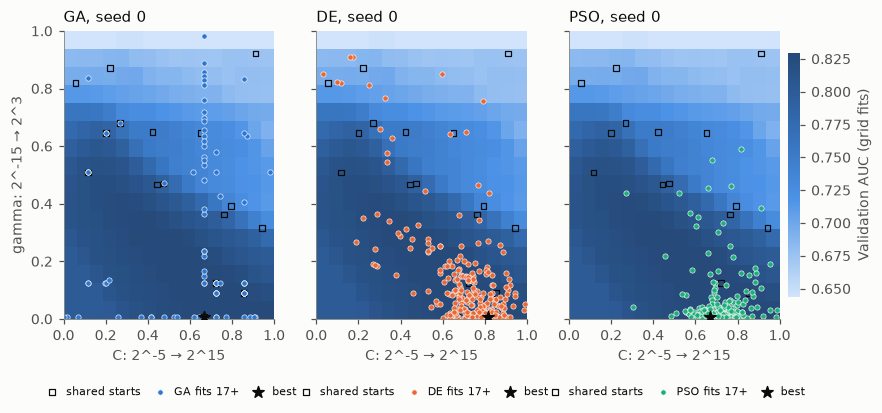

In [4]:
fig = plots.fig_svm_landscape(curves, seed=0)
if fig:
    plots.save(fig, FIGS, "nb08_svm_landscape")

## AUC vs wall-clock time (own reading only)

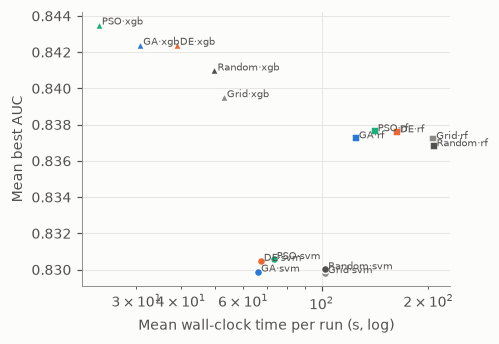

In [5]:
fig = plots.fig_auc_vs_time(stats.summary_table(runs))
plots.save(fig, FIGS, "nb08_auc_vs_time")